**STAGE 1**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load competition datasets
DATA_DIR = "/kaggle/input/competitions/house-prices-advanced-regression-techniques"
train_df = pd.read_csv(DATA_DIR + "/train.csv")
test_df = pd.read_csv(DATA_DIR + "/test.csv")

print(f"Train Dataset Shape: {train_df.shape}")
print(f"Test Dataset Shape:  {test_df.shape}")
train_df.head()

Train Dataset Shape: (1460, 81)
Test Dataset Shape:  (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Original SalePrice Skewness: 1.8829
Original SalePrice Kurtosis: 6.5363


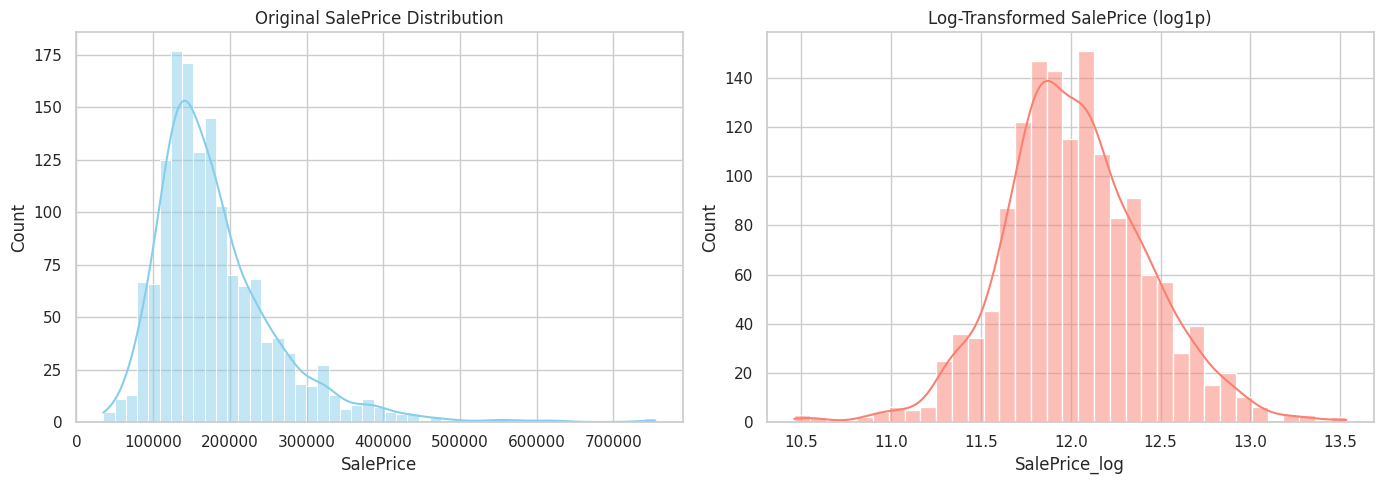

Log-Transformed SalePrice Skewness: 0.1213
Log-Transformed SalePrice Kurtosis: 0.8095


In [3]:
# Measure skewness & kurtosis of raw target
orig_skew = train_df['SalePrice'].skew()
orig_kurt = train_df['SalePrice'].kurt()
print(f"Original SalePrice Skewness: {orig_skew:.4f}")
print(f"Original SalePrice Kurtosis: {orig_kurt:.4f}")

# Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw target distribution
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Original SalePrice Distribution")

# Apply Log Transformation (log1p)
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
log_skew = train_df['SalePrice_log'].skew()
log_kurt = train_df['SalePrice_log'].kurt()

sns.histplot(train_df['SalePrice_log'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title("Log-Transformed SalePrice (log1p)")

plt.tight_layout()
plt.show()

print(f"Log-Transformed SalePrice Skewness: {log_skew:.4f}")
print(f"Log-Transformed SalePrice Kurtosis: {log_kurt:.4f}")

In [4]:
def check_missing_values(df, dataset_name="Dataset"):
    null_counts = df.isnull().sum()
    null_pct = (null_counts / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': null_counts, 'Missing Pct (%)': null_pct})
    missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
    print(f"=== {dataset_name}: {len(missing_df)} features contain missing values ===")
    return missing_df

train_missing = check_missing_values(train_df, "Train Set")
print(train_missing.head(10))

test_missing = check_missing_values(test_df, "Test Set")
print(test_missing.head(10))

=== Train Set: 19 features contain missing values ===
              Missing Count  Missing Pct (%)
PoolQC                 1453        99.520548
MiscFeature            1406        96.301370
Alley                  1369        93.767123
Fence                  1179        80.753425
MasVnrType              872        59.726027
FireplaceQu             690        47.260274
LotFrontage             259        17.739726
GarageType               81         5.547945
GarageYrBlt              81         5.547945
GarageFinish             81         5.547945
=== Test Set: 33 features contain missing values ===
             Missing Count  Missing Pct (%)
PoolQC                1456        99.794380
MiscFeature           1408        96.504455
Alley                 1352        92.666210
Fence                 1169        80.123372
MasVnrType             894        61.274846
FireplaceQu            730        50.034270
LotFrontage            227        15.558602
GarageQual              78         5.346127
Ga

Numerical Features Count: 39
Categorical Features Count: 43


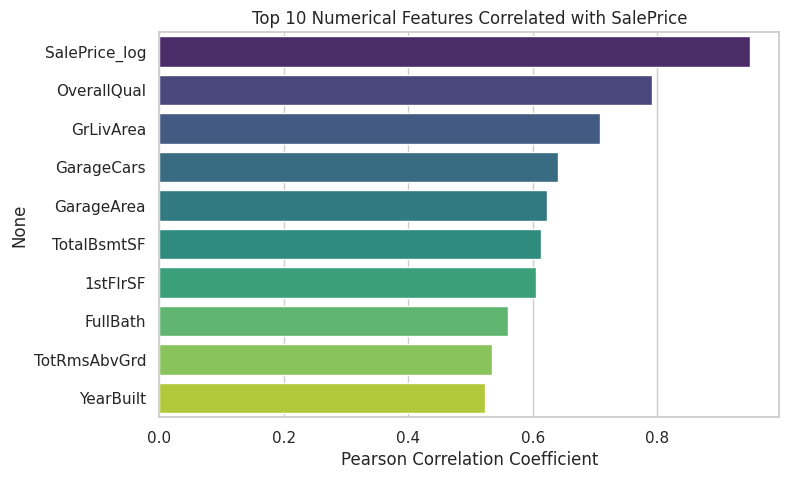

In [5]:
# Distinguish numerical vs categorical feature types
num_features = train_df.select_dtypes(include=[np.number]).columns.tolist()
cat_features = train_df.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical Features Count: {len(num_features)}")
print(f"Categorical Features Count: {len(cat_features)}")

# Rank top numerical features correlated with raw SalePrice
corr_matrix = train_df[num_features].corr()
top_corr = corr_matrix['SalePrice'].sort_values(ascending=False)[1:11]

plt.figure(figsize=(8, 5))
sns.barplot(x=top_corr.values, y=top_corr.index, hue=top_corr.index, legend=False, palette="viridis")
plt.title("Top 10 Numerical Features Correlated with SalePrice")
plt.xlabel("Pearson Correlation Coefficient")
plt.show()

**STAGE 2**

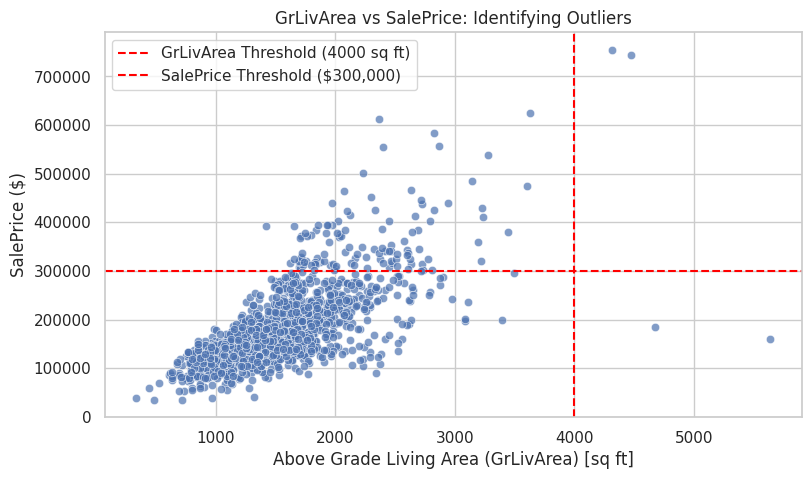

,GrLivArea,SalePrice,OverallQual,Neighborhood
523,4676,184750,10,Edwards
1298,5642,160000,10,Edwards


In [6]:
# 1. Visual Scatter Plot
plt.figure(figsize=(9, 5))
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=0.7)

# Threshold lines for visual inspection
plt.axvline(x=4000, color='red', linestyle='--', label='GrLivArea Threshold (4000 sq ft)')
plt.axhline(y=300000, color='red', linestyle='--', label='SalePrice Threshold ($300,000)')

plt.title("GrLivArea vs SalePrice: Identifying Outliers")
plt.xlabel("Above Grade Living Area (GrLivArea) [sq ft]")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

# 2. Query the exact rows in the bottom-right quadrant
outliers_df = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
outliers_df[['GrLivArea', 'SalePrice', 'OverallQual', 'Neighborhood']]

In [7]:
# Drop the 2 well-known extreme outliers in GrLivArea
train_df = train_df.drop(
    train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)].index
).reset_index(drop=True)

print(f"Train Dataset Shape after outlier removal: {train_df.shape}")

Train Dataset Shape after outlier removal: (1458, 82)


In [41]:
# Isolate targets and identifiers
train_y = train_df['SalePrice_log']
train_id = train_df['Id']
test_id = test_df['Id']

# Combine features across train and test sets
all_data = pd.concat([
    train_df.drop(columns=['Id', 'SalePrice', 'SalePrice_log']),
    test_df.drop(columns=['Id'])
], axis=0).reset_index(drop=True)

print(f"Combined Features Shape: {all_data.shape}")

Combined Features Shape: (2917, 79)


In [42]:
# Diagnostic Cell: Data-Driven Missing Value Analysis

# 1. Inventory all columns with missing values in combined dataset
missing_info = []
for col in all_data.columns:
    null_cnt = all_data[col].isnull().sum()
    if null_cnt > 0:
        missing_info.append({
            'Column': col,
            'Data Type': all_data[col].dtype,
            'Missing Count': null_cnt,
            'Missing Pct (%)': round((null_cnt / len(all_data)) * 100, 2),
            'Sample Non-Null Values': list(all_data[col].dropna().unique()[:4])
        })

missing_analysis_df = pd.DataFrame(missing_info).sort_values(by='Missing Count', ascending=False)
print("=== MISSING VALUE INVENTORY ===")
print(missing_analysis_df.to_string(index=False))

# 2. Query data_description.txt for official definition of 'NA' across key features
print("\n" + "="*50)
print("=== EXTRACTING NA DEFINITIONS FROM DATA_DESCRIPTION.TXT ===")
print("="*50)

with open(DATA_DIR + "/data_description.txt", "r") as f:
    desc_text = f.read()

# Search documentation for categorical features with missing values
sample_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'BsmtQual', 'GarageType']
for col in sample_cols:
    start_idx = desc_text.find(col + ":")
    if start_idx != -1:
        # Print the section from data_description.txt
        snippet = desc_text[start_idx : start_idx + 250]
        print(snippet.strip())
        print("-" * 50)

=== MISSING VALUE INVENTORY ===
      Column Data Type  Missing Count  Missing Pct (%)               Sample Non-Null Values
      PoolQC    object           2908            99.69                         [Ex, Fa, Gd]
 MiscFeature    object           2812            96.40             [Shed, Gar2, Othr, TenC]
       Alley    object           2719            93.21                         [Grvl, Pave]
       Fence    object           2346            80.43           [MnPrv, GdWo, GdPrv, MnWw]
  MasVnrType    object           1766            60.54             [BrkFace, Stone, BrkCmn]
 FireplaceQu    object           1420            48.68                     [TA, Gd, Fa, Ex]
 LotFrontage   float64            486            16.66             [65.0, 80.0, 68.0, 60.0]
  GarageQual    object            159             5.45                     [TA, Fa, Gd, Ex]
 GarageYrBlt   float64            159             5.45     [2003.0, 1976.0, 2001.0, 1998.0]
  GarageCond    object            159           

In [43]:
# 1. Categorical attributes where NA indicates "None / Absence of Amenity"
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType'
]
all_data[none_cols] = all_data[none_cols].fillna('None')

# 2. Categorical attributes with genuine missing values: Impute via Mode
mode_cols = [
    'MSZoning', 'Utilities', 'Exterior1st', 'Exterior2nd',
    'Electrical', 'KitchenQual', 'Functional', 'SaleType'
]
for col in mode_cols:
    all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

# 3. Numerical attributes where NA indicates missing structure/area: Impute with 0
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea'
]
all_data[zero_cols] = all_data[zero_cols].fillna(0)

# 4. LotFrontage: Impute missing values using the median LotFrontage of the specific Neighborhood
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

In [44]:
remaining_nulls = all_data.isnull().sum().sum()
print(f"Total Remaining Missing Values in Combined Features: {remaining_nulls}")

if remaining_nulls > 0:
    print("\nColumns with remaining missing values:")
    print(all_data.isnull().sum()[all_data.isnull().sum() > 0])
else:
    print("All missing values successfully resolved across all 2,917 rows!")

Total Remaining Missing Values in Combined Features: 0
All missing values successfully resolved across all 2,917 rows!


**STAGE 3**

In [45]:
# 1. Total Living Area Metric (TotalSF)
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']

# 2. Total Bathrooms Metric
all_data['TotalBaths'] = (
    all_data['FullBath'] + (0.5 * all_data['HalfBath']) +
    all_data['BsmtFullBath'] + (0.5 * all_data['BsmtHalfBath'])
)

# 3. Total Outdoor/Porch Deck Square Footage
all_data['TotalPorchSF'] = (
    all_data['OpenPorchSF'] + all_data['EnclosedPorch'] +
    all_data['3SsnPorch'] + all_data['ScreenPorch'] + all_data['WoodDeckSF']
)

# 4. Property Age Metrics (Clipped at 0 to eliminate negative age values)
all_data['HouseAge'] = np.maximum(0, all_data['YrSold'] - all_data['YearBuilt'])
all_data['RemodelAge'] = np.maximum(0, all_data['YrSold'] - all_data['YearRemodAdd'])
all_data['IsRemodeled'] = (all_data['YearBuilt'] != all_data['YearRemodAdd']).astype(int)
all_data['IsNew'] = (all_data['YrSold'] == all_data['YearBuilt']).astype(int)

# 5. Presence Flags for Key Amenities
all_data['HasGarage'] = (all_data['GarageArea'] > 0).astype(int)
all_data['HasBsmt'] = (all_data['TotalBsmtSF'] > 0).astype(int)
all_data['HasFireplace'] = (all_data['Fireplaces'] > 0).astype(int)
all_data['HasPool'] = (all_data['PoolArea'] > 0).astype(int)

# 6. Neighborhood Spatial Aggregations
all_data['GrLivArea_to_NeighMedian'] = all_data['GrLivArea'] / all_data.groupby('Neighborhood')['GrLivArea'].transform('median')
all_data['TotalSF_to_NeighMedian']   = all_data['TotalSF'] / all_data.groupby('Neighborhood')['TotalSF'].transform('median')
all_data['Neigh_OverallQual_Mean']   = all_data.groupby('Neighborhood')['OverallQual'].transform('mean')
all_data['Neigh_TotalSF_Median']     = all_data.groupby('Neighborhood')['TotalSF'].transform('median')

# 7. Interaction Terms
all_data['Qual_x_TotalSF']    = all_data['OverallQual'] * all_data['TotalSF']
all_data['Cond_x_Age']        = all_data['OverallCond'] * all_data['HouseAge']
all_data['Baths_per_TotalSF'] = all_data['TotalBaths'] / (all_data['TotalSF'] + 1)

print(f"Features created successfully! Total features: {all_data.shape[1]}")

Features created successfully! Total features: 97


In [46]:
# Map ordinal quality categories to numeric scales
qual_dict = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
qual_cols = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
    'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC'
]

for col in qual_cols:
    all_data[col] = all_data[col].map(qual_dict).fillna(0).astype(int)

# Map basement exposure scale
all_data['BsmtExposure'] = all_data['BsmtExposure'].map(
    {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
).fillna(0).astype(int)

# Compute Composite Quality Index using pre-mapped numeric columns
all_data['Total_Qual_Index'] = (
    all_data['OverallQual'] + all_data['ExterQual'] + all_data['KitchenQual'] + all_data['BsmtQual']
)

# Normalize highly skewed continuous numerical features safely
numeric_feats = all_data.select_dtypes(include=[np.number]).columns
skewed_feats = all_data[numeric_feats].apply(lambda x: x.skew()).sort_values(ascending=False)

high_skew = skewed_feats[abs(skewed_feats) > 0.75].index

for col in high_skew:
    all_data[col] = np.log1p(np.maximum(0, all_data[col]))

print(f"Log-transformed {len(high_skew)} highly skewed numerical features with zero NaNs!")

Log-transformed 41 highly skewed numerical features with zero NaNs!


In [47]:
# Apply dummy encoding to remaining nominal categorical variables
all_data = pd.get_dummies(all_data, drop_first=True)

# Sanitize feature names (XGBoost throws errors on characters like '[', ']', and '<')
import re
all_data.columns = [re.sub(r'[\[\]<,]', '_', col) for col in all_data.columns]

print(f"Total features after One-Hot Encoding: {all_data.shape[1]}")

Total features after One-Hot Encoding: 244


In [48]:
# Separate combined dataset back into training and testing features
num_train = len(train_y)
X_train = all_data.iloc[:num_train].copy()
X_test = all_data.iloc[num_train:].copy()

print(f"X_train Shape: {X_train.shape}")
print(f"y_train Shape: {train_y.shape}")
print(f"X_test Shape:  {X_test.shape}")

# Assert validity checks
assert X_train.isnull().sum().sum() == 0, "Null values remain in X_train!"
assert X_test.isnull().sum().sum() == 0, "Null values remain in X_test!"
assert X_train.shape[1] == X_test.shape[1], "Feature dimension mismatch between train and test!"

print("\nPreprocessed datasets verified and ready for model training!")

X_train Shape: (1458, 244)
y_train Shape: (1458,)
X_test Shape:  (1459, 244)

Preprocessed datasets verified and ready for model training!


**STAGE 4**

In [49]:
import xgboost as xgb
from sklearn.model_selection import KFold, cross_val_score, RandomizedSearchCV
from sklearn.metrics import mean_squared_error

# Establish 5-Fold Cross-Validation strategy
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluation function to compute K-Fold RMSLE
def get_rmsle_cv(model, X, y):
    rmse_scores = np.sqrt(-cross_val_score(
        model, X, y, 
        scoring="neg_mean_squared_error", 
        cv=kf
    ))
    return rmse_scores

# Test baseline untuned XGBoost model
baseline_xgb = xgb.XGBRegressor(random_state=42, n_jobs=-1)
baseline_scores = get_rmsle_cv(baseline_xgb, X_train, train_y)

print(f"Baseline XGBoost RMSLE: {baseline_scores.mean():.5f} (+/- {baseline_scores.std():.5f})")

Baseline XGBoost RMSLE: 0.13357 (+/- 0.00736)


In [50]:
# Define hyperparameter Search Grid
param_grid = {
    'n_estimators': [500, 1000, 1500, 2000],
    'learning_rate': [0.01, 0.015, 0.02, 0.05],
    'max_depth': [3, 4, 5, 6],
    'min_child_weight': [1, 2, 3, 5],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [0.4, 0.5, 0.6, 0.7],
    'reg_alpha': [0.001, 0.01, 0.1, 1.0],
    'reg_lambda': [0.1, 0.5, 1.0, 2.0]
}

# Configure RandomizedSearchCV
xgb_search = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=20,  # 20 random hyperparameter combinations
    scoring='neg_mean_squared_error',
    cv=kf,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Starting Hyperparameter Search...")
xgb_search.fit(X_train, train_y)

print("\nBest Parameters Found:")
for param, val in xgb_search.best_params_.items():
    print(f"  {param}: {val}")

Starting Hyperparameter Search...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters Found:
  subsample: 0.7
  reg_lambda: 0.1
  reg_alpha: 0.1
  n_estimators: 1500
  min_child_weight: 1
  max_depth: 3
  learning_rate: 0.02
  colsample_bytree: 0.4


In [51]:
# Extract the tuned model
best_xgb = xgb.XGBRegressor(**xgb_search.best_params_, random_state=42, n_jobs=-1)

# Evaluate cross-validation score of tuned model
tuned_scores = get_rmsle_cv(best_xgb, X_train, train_y)
print(f"Tuned XGBoost 5-Fold RMSLE: {tuned_scores.mean():.5f} (+/- {tuned_scores.std():.5f})")

# Fit tuned model on the entire training set
best_xgb.fit(X_train, train_y)

# Generate log-scale test predictions
xgb_test_preds = best_xgb.predict(X_test)
print(f"Generated {len(xgb_test_preds)} XGBoost test predictions successfully!")

Tuned XGBoost 5-Fold RMSLE: 0.11476 (+/- 0.00731)
Generated 1459 XGBoost test predictions successfully!


/tmp/ipykernel_49/2309393576.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance.head(15), x='Importance', y='Feature', palette='crest')


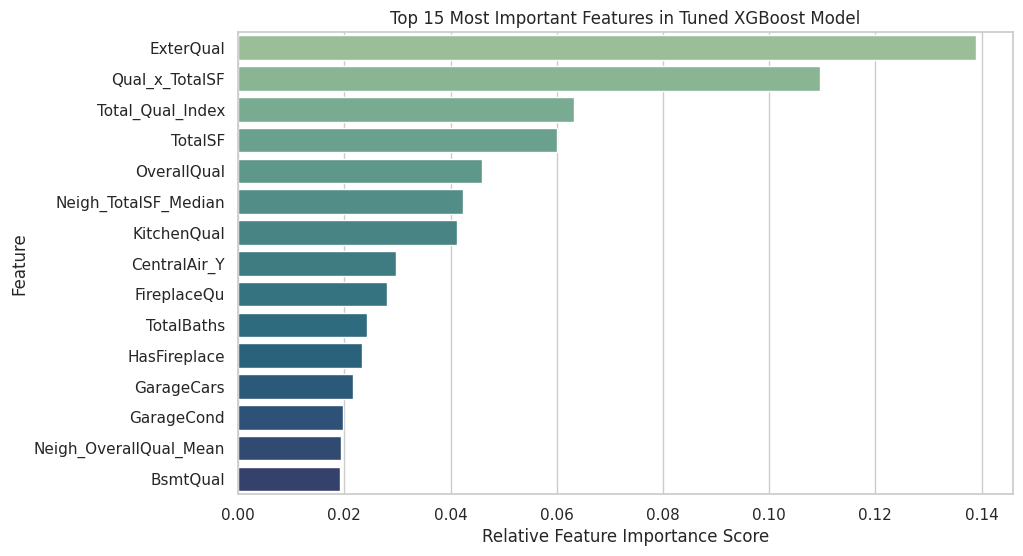

             Feature  Importance
           ExterQual    0.138997
      Qual_x_TotalSF    0.109562
    Total_Qual_Index    0.063284
             TotalSF    0.060043
         OverallQual    0.045885
Neigh_TotalSF_Median    0.042324
         KitchenQual    0.041281
        CentralAir_Y    0.029816
         FireplaceQu    0.027998
          TotalBaths    0.024317


In [52]:
# Top 15 most influential features
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance.head(15), x='Importance', y='Feature', palette='crest')
plt.title("Top 15 Most Important Features in Tuned XGBoost Model")
plt.xlabel("Relative Feature Importance Score")
plt.show()

print(feature_importance.head(10).to_string(index=False))

**STAGE 5**

In [53]:
from sklearn.preprocessing import StandardScaler

# Scale features to zero mean and unit variance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify no NaN or Inf values exist after scaling
assert not np.isnan(X_train_scaled).any(), "NaN values found in X_train_scaled!"
assert not np.isnan(X_test_scaled).any(), "NaN values found in X_test_scaled!"

print("Feature scaling verified! Zero NaNs or infinite values found.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")

Feature scaling verified! Zero NaNs or infinite values found.
X_train_scaled shape: (1458, 244)


In [54]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

tf.random.set_seed(42)
np.random.seed(42)

# Calculate target mean to initialize neural network output bias
y_mean_init = float(train_y.mean())

def build_ann_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        
        # Layer 1
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
        layers.Dropout(0.2),
        
        # Layer 2
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
        layers.Dropout(0.2),
        
        # Layer 3
        layers.Dense(32, activation='relu'),
        
        # Linear output layer initialized directly to the target mean (~12.02)
        layers.Dense(1, bias_initializer=tf.keras.initializers.Constant(y_mean_init))
    ])
    
    # Smaller learning rate ensures smooth convergence
    optimizer = keras.optimizers.Adam(learning_rate=0.0005)
    
    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error'
    )
    return model

print(f"Target mean output bias set to: {y_mean_init:.4f}")
print("Keras ANN architecture with target bias initialization defined successfully!")

Target mean output bias set to: 12.0240
Keras ANN architecture with target bias initialization defined successfully!


In [64]:
ann_cv_scores = []
ann_test_preds = np.zeros(len(X_test_scaled))

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=25,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=8,
    min_lr=1e-5
)

print("Training updated Keras ANN across 5 folds...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_scaled, train_y)):
    X_tr, y_tr = X_train_scaled[train_idx], train_y.iloc[train_idx]
    X_va, y_va = X_train_scaled[val_idx], train_y.iloc[val_idx]
    
    model = build_ann_model(X_train_scaled.shape[1])
    
    model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=300,
        batch_size=32,
        callbacks=[early_stopping, reduce_lr],
        verbose=0
    )
    
    val_preds = model.predict(X_va, verbose=0).flatten()
    fold_rmsle = np.sqrt(mean_squared_error(y_va, val_preds))
    ann_cv_scores.append(fold_rmsle)
    
    print(f"  Fold {fold + 1} RMSLE: {fold_rmsle:.5f}")
    
    ann_test_preds += model.predict(X_test_scaled, verbose=0).flatten() / kf.n_splits

print(f"\nOverall Keras ANN 5-Fold RMSLE: {np.mean(ann_cv_scores):.5f} (+/- {np.std(ann_cv_scores):.5f})")

Training updated Keras ANN across 5 folds...
  Fold 1 RMSLE: 0.12694
  Fold 2 RMSLE: 0.35828
  Fold 3 RMSLE: 0.26707
  Fold 4 RMSLE: 0.26782
  Fold 5 RMSLE: 0.27166

Overall Keras ANN 5-Fold RMSLE: 0.25835 (+/- 0.07429)


**IMPROVEMENTS**

In [65]:
from sklearn.linear_model import LassoCV, RidgeCV

# 1. Train & Tune Lasso (L1 Regularization - performs built-in feature selection)
alphas_lasso = np.logspace(-4, -1, 30)
lasso = LassoCV(alphas=alphas_lasso, cv=kf, max_iter=10000, random_state=42)
lasso.fit(X_train_scaled, train_y)

lasso_scores = get_rmsle_cv(lasso, X_train_scaled, train_y)
print(f"Lasso 5-Fold RMSLE: {lasso_scores.mean():.5f} (+/- {lasso_scores.std():.5f}) [Best Alpha: {lasso.alpha_:.5f}]")

# 2. Train & Tune Ridge (L2 Regularization - shrinks correlated coefficients)
alphas_ridge = np.logspace(1, 3, 30)
ridge = RidgeCV(alphas=alphas_ridge, cv=kf)
ridge.fit(X_train_scaled, train_y)

ridge_scores = get_rmsle_cv(ridge, X_train_scaled, train_y)
print(f"Ridge 5-Fold RMSLE: {ridge_scores.mean():.5f} (+/- {ridge_scores.std():.5f}) [Best Alpha: {ridge.alpha_:.5f}]")

# Generate test predictions
lasso_test_preds = lasso.predict(X_test_scaled)
ridge_test_preds = ridge.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.017456145085744446, tolerance: 0.014057857022714882
  model = cd_fast.enet_coordinate_descent_gram(


Lasso 5-Fold RMSLE: 0.11615 (+/- 0.00834) [Best Alpha: 0.00356]
Ridge 5-Fold RMSLE: 0.11841 (+/- 0.00856) [Best Alpha: 239.50266]


In [73]:
from catboost import CatBoostRegressor

# Define CatBoost with conservative depth to prevent overfitting
cat_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.02,
    depth=5,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

# Compute 5-Fold Cross-Validation RMSLE
cat_scores = get_rmsle_cv(cat_model, X_train, train_y)
print(f"CatBoost 5-Fold RMSLE: {cat_scores.mean():.5f} (+/- {cat_scores.std():.5f})")

# Fit on full dataset & generate test predictions
cat_model.fit(X_train, train_y)
cat_test_preds = cat_model.predict(X_test)

CatBoost 5-Fold RMSLE: 0.11366 (+/- 0.00776)


In [66]:
import lightgbm as lgb

# Define LightGBM with parameters tuned for high-dimensional tabular datasets
lgb_model = lgb.LGBMRegressor(
    n_estimators=1500,
    learning_rate=0.015,
    num_leaves=15,
    max_depth=4,
    subsample=0.7,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# Evaluate 5-Fold Cross Validation RMSLE
lgb_scores = get_rmsle_cv(lgb_model, X_train, train_y)
print(f"LightGBM 5-Fold RMSLE: {lgb_scores.mean():.5f} (+/- {lgb_scores.std():.5f})")

# Fit on full training set and generate test predictions
lgb_model.fit(X_train, train_y)
lgb_test_preds = lgb_model.predict(X_test)

LightGBM 5-Fold RMSLE: 0.11779 (+/- 0.00804)


In [74]:
from sklearn.model_selection import cross_val_predict
from scipy.optimize import minimize

print("Generating Out-Of-Fold (OOF) predictions across all 5 models...")

# 1. Generate OOF validation predictions for all 5 model architectures
oof_xgb   = cross_val_predict(best_xgb, X_train, train_y, cv=kf)
oof_lgb   = cross_val_predict(lgb_model, X_train, train_y, cv=kf)
oof_cat   = cross_val_predict(cat_model, X_train, train_y, cv=kf)
oof_lasso = cross_val_predict(lasso, X_train_scaled, train_y, cv=kf)
oof_ridge = cross_val_predict(ridge, X_train_scaled, train_y, cv=kf)

# Stack OOF and Test predictions into 5-column matrices
oof_matrix = np.column_stack([oof_xgb, oof_lgb, oof_cat, oof_lasso, oof_ridge])
test_matrix = np.column_stack([xgb_test_preds, lgb_test_preds, cat_test_preds, lasso_test_preds, ridge_test_preds])

# 2. Objective function: Minimize overall global RMSLE
def ensemble_loss(weights):
    weights = weights / np.sum(weights)
    blend_oof = np.dot(oof_matrix, weights)
    return np.sqrt(mean_squared_error(train_y, blend_oof))

# Initial equal weights & non-negative sum constraint
init_weights = [0.20, 0.20, 0.20, 0.20, 0.20]
bounds = [(0, 1)] * 5
constraints = ({'type': 'eq', 'fun': lambda w: 1.0 - np.sum(w)})

# Solve for exact mathematical weights
res = minimize(ensemble_loss, init_weights, method='SLSQP', bounds=bounds, constraints=constraints)
opt_weights = res.x / np.sum(res.x)
model_names = ['XGBoost', 'LightGBM', 'CatBoost', 'Lasso', 'Ridge']

print("\n=== OPTIMAL 5-MODEL WEIGHTS ===")
for name, w in zip(model_names, opt_weights):
    print(f"  {name:10s}: {w*100:.2f}%")

opt_oof_rmsle = ensemble_loss(opt_weights)
print(f"\nOptimized 5-Model OOF RMSLE: {opt_oof_rmsle:.5f}")

# 3. Generate final blended test set predictions and export
final_log_preds = np.dot(test_matrix, opt_weights)
final_prices = np.expm1(final_log_preds)


Generating Out-Of-Fold (OOF) predictions across all 5 models...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.017456145085744446, tolerance: 0.014057857022714882
  model = cd_fast.enet_coordinate_descent_gram(



=== OPTIMAL 5-MODEL WEIGHTS ===
  XGBoost   : 20.65%
  LightGBM  : 7.92%
  CatBoost  : 31.80%
  Lasso     : 23.76%
  Ridge     : 15.87%

Optimized 5-Model OOF RMSLE: 0.11133


**STAGE 6**

In [75]:
# Create submission DataFrame matching Kaggle requirements
submission = pd.DataFrame({
    'Id': test_id,
    'SalePrice': final_prices
})

# Export to working directory
submission.to_csv('submission.csv', index=False)
print("submission.csv successfully generated and saved!")

submission.csv successfully generated and saved!


In [76]:
# Verify file exists and inspect structure
sub_check = pd.read_csv('submission.csv')

print(f"Submission File Shape: {sub_check.shape}")
print(f"Null Values Present:   {sub_check.isnull().sum().sum()}")
print(f"Minimum SalePrice:    ${sub_check['SalePrice'].min():,.2f}")
print(f"Maximum SalePrice:    ${sub_check['SalePrice'].max():,.2f}")
print(f"Mean SalePrice:       ${sub_check['SalePrice'].mean():,.2f}")

# Assert standard Kaggle checks
assert sub_check.shape == (1459, 2), "Incorrect submission dimensions!"
assert sub_check.isnull().sum().sum() == 0, "Submission contains missing values!"
assert (sub_check['SalePrice'] > 0).all(), "Submission contains non-positive price predictions!"

print("\nAll submission integrity checks passed successfully! Ready to submit on Kaggle.")
sub_check.head(10)

Submission File Shape: (1459, 2)
Null Values Present:   0
Minimum SalePrice:    $49,718.09
Maximum SalePrice:    $622,537.05
Mean SalePrice:       $178,029.98

All submission integrity checks passed successfully! Ready to submit on Kaggle.


,Id,SalePrice
0,1461,121836.610208
1,1462,161415.303258
2,1463,181097.313282
3,1464,194534.796134
4,1465,192495.946756
5,1466,171356.337861
6,1467,174886.540778
7,1468,164508.394616
8,1469,188754.588299
9,1470,120506.772319


**HOW**

In [70]:
import shap

# Initialize TreeExplainer with the trained XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# Compute SHAP values for the training feature set
shap_values = explainer(X_train)

print("SHAP values calculated successfully across all training samples!")

SHAP values calculated successfully across all training samples!


/tmp/ipykernel_49/1194853368.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_train, max_display=15, show=False)


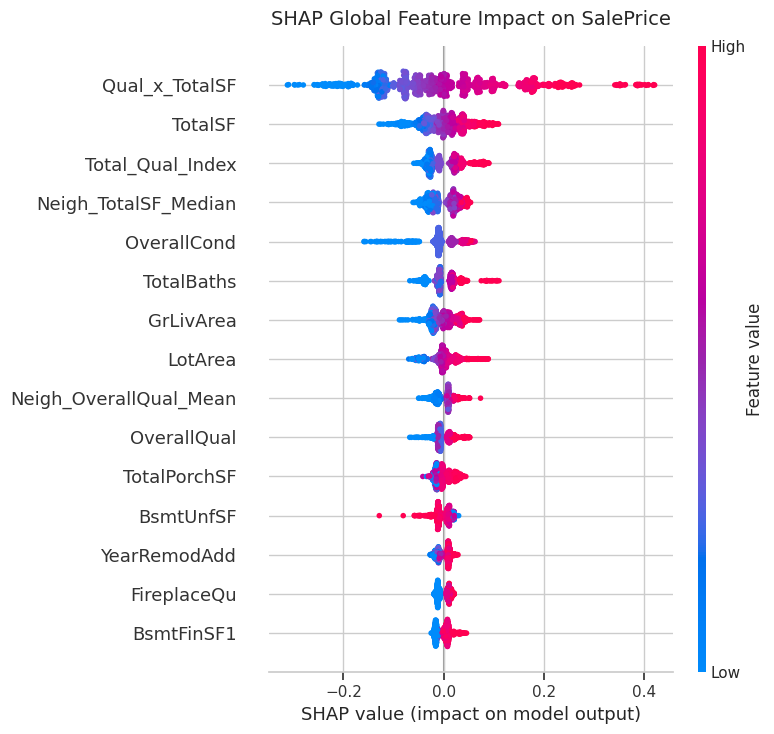

In [71]:
import matplotlib.pyplot as plt

# Set plot size
plt.figure(figsize=(10, 6))

# Generate beeswarm summary plot for top 15 features
shap.summary_plot(shap_values, X_train, max_display=15, show=False)
plt.title("SHAP Global Feature Impact on SalePrice", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

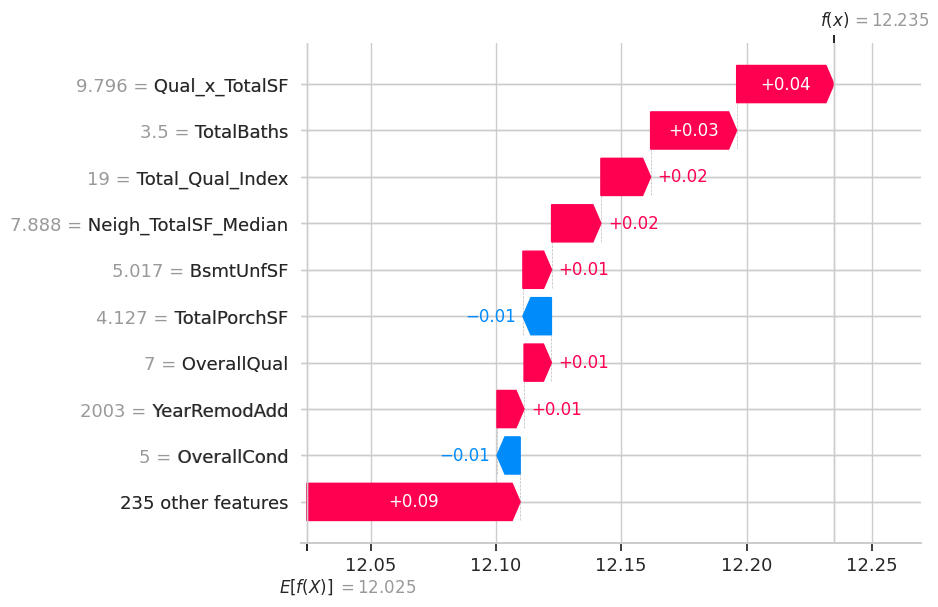

In [72]:
# Explain prediction for the first house in the training dataset (index 0)
sample_idx = 0

# Set plot dimensions
plt.figure(figsize=(9, 6))

# Generate waterfall plot
shap.plots.waterfall(shap_values[sample_idx], max_display=10)